# EDA das avaliações Olist: o que cada comentário nos diz e o que sobra como documento

Trabalhamos com a unidade **1 avaliação com texto = 1 documento recuperável**: o que importa é o texto (título e mensagem), a nota e os metadados do pedido (entrega e categoria). Esta EDA apoia diretamente as decisões da preparação da base e do índice.

In [1]:
import sys, re
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
IMAGES_DIR = ROOT / "images"
IMAGES_DIR.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import DATA_RAW

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
plt.style.use("seaborn-v0_8-whitegrid")
AZUL, VERDE, VERMELHO, LARANJA = "#4C72B0", "#55A868", "#C44E52", "#DD8452"

rev = pd.read_csv(DATA_RAW / "olist_order_reviews_dataset.csv")
print("df.shape:", rev.shape)
print(rev.dtypes.to_string())

df.shape: (99224, 7)
review_id                    str
order_id                     str
review_score               int64
review_comment_title         str
review_comment_message       str
review_creation_date         str
review_answer_timestamp      str


## 1. Carga e volumes

O arquivo tem **99.224 linhas e 7 colunas** (`review_id`, `order_id`, `review_score`, `review_comment_title`, `review_comment_message`, `review_creation_date`, `review_answer_timestamp`). Tratamos texto vazio ou só com espaços como ausente e medimos quantas avaliações têm título, mensagem ou algum dos dois.

In [2]:
def limpa(s):
    return s.fillna("").astype(str).str.strip()

rev["titulo"] = limpa(rev["review_comment_title"])
rev["mensagem"] = limpa(rev["review_comment_message"])
rev["tem_titulo"] = rev["titulo"].ne("")
rev["tem_msg"] = rev["mensagem"].ne("")
rev["tem_texto"] = rev["tem_titulo"] | rev["tem_msg"]

vol = pd.DataFrame({"n": [rev.tem_titulo.sum(), rev.tem_msg.sum(), rev.tem_texto.sum(), (rev.tem_titulo & rev.tem_msg).sum()]},
                   index=["com título", "com mensagem", "com título OU mensagem", "com título E mensagem"])
vol["%"] = (100 * vol["n"] / len(rev)).round(2)
vol

,n,%
com título,11566,11.66
com mensagem,40950,41.27
com título OU mensagem,42687,43.02
com título E mensagem,9829,9.91


**Apenas 43,02% das linhas (42.687) têm algum texto.** A `review_comment_message` está em 41,27% e o `review_comment_title` em só 11,66%; os dois juntos aparecem em 9,91%. Isso mostra que o título é um complemento raro e que a mensagem é o conteúdo principal do documento. Os 57% sem texto não entram no índice, pois não há o que recuperar.

## 2. Duplicatas

No arquivo original, o mesmo `review_id` pode aparecer ligado a mais de um `order_id`. Checamos se são avaliações distintas ou a mesma avaliação repetida.

In [3]:
dup_mask = rev.duplicated("review_id", keep=False)
print("review_id únicos:", f"{rev.review_id.nunique():,}")
print("review_id que aparecem mais de uma vez:", rev.loc[dup_mask, "review_id"].nunique())
print("linhas excedentes (removidas ao deduplicar):", len(rev) - rev.review_id.nunique())
print("pares (review_id, order_id) únicos:", len(rev.drop_duplicates(["review_id", "order_id"])), "de", len(rev), "linhas")
print("linhas com order_id repetido (pedido com 2+ avaliações):", int(rev.order_id.duplicated().sum()))

g = rev[dup_mask].groupby("review_id")
iguais = g.agg(n_msg=("mensagem", "nunique"), n_tit=("titulo", "nunique"),
               n_nota=("review_score", "nunique"), n_ped=("order_id", "nunique"))
print("\nEntre os ids repetidos:")
print("  mensagem idêntica em todas as cópias:", int((iguais.n_msg == 1).sum()), "de", len(iguais))
print("  título idêntico:", int((iguais.n_tit == 1).sum()), "| nota idêntica:", int((iguais.n_nota == 1).sum()))
print("  cópias ligadas a pedidos distintos:", int((iguais.n_ped > 1).sum()))
print("  nº de cópias por id:", g.size().value_counts().to_dict())

review_id únicos: 98,410
review_id que aparecem mais de uma vez: 789
linhas excedentes (removidas ao deduplicar): 814
pares (review_id, order_id) únicos: 99224 de 99224 linhas
linhas com order_id repetido (pedido com 2+ avaliações): 551



Entre os ids repetidos:
  mensagem idêntica em todas as cópias: 789 de 789
  título idêntico: 789 | nota idêntica: 789
  cópias ligadas a pedidos distintos: 789
  nº de cópias por id: {2: 764, 3: 25}


**Insight confirmado:** os **789 `review_id` repetidos (1.603 linhas)** são a mesma avaliação ligada a pedidos diferentes: em todos, `review_comment_message`, `review_comment_title` e `review_score` são idênticos, e só o `order_id` muda. Mantemos **uma linha por `review_id`**, o que leva de 99.224 para **98.410** avaliações (814 linhas excedentes). Um efeito colateral é que a categoria dessa avaliação depende do pedido escolhido; voltamos a isso na seção 6.

## 3. Notas

Comparamos a distribuição de `review_score` no conjunto todo (já deduplicado) com a distribuição entre as avaliações que têm texto. A hipótese é que notas baixas tenham proporcionalmente mais texto.

              total  % do total  com texto  % dos com texto  % da nota com texto
review_score                                                                    
1             11282        11.5       8723             20.6                 77.3
2              3114         3.2       2138              5.0                 68.7
3              8097         8.2       3614              8.5                 44.6
4             19007        19.3       6237             14.7                 32.8
5             56910        57.8      21658             51.1                 38.1

Total: 98410 | com texto: 42370 (43.1%)


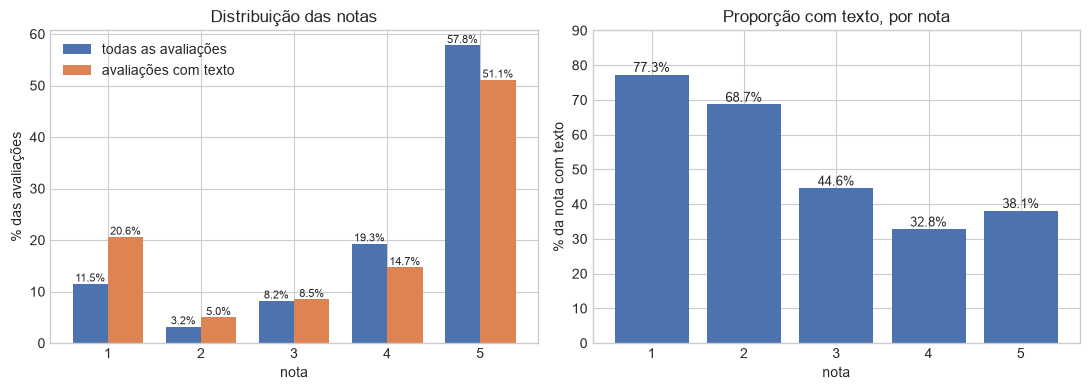

In [4]:
u = rev.drop_duplicates("review_id").copy()
geral = u.review_score.value_counts().sort_index()
com_txt = u[u.tem_texto].review_score.value_counts().sort_index()
tab = pd.DataFrame({"total": geral, "% do total": (100 * geral / geral.sum()).round(1),
                    "com texto": com_txt, "% dos com texto": (100 * com_txt / com_txt.sum()).round(1)})
tab["% da nota com texto"] = (100 * tab["com texto"] / tab["total"]).round(1)
print(tab.to_string())
print("\nTotal:", int(tab.total.sum()), "| com texto:", int(tab["com texto"].sum()),
      f"({100*tab['com texto'].sum()/tab.total.sum():.1f}%)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(1, 6); w = 0.38
b1 = ax[0].bar(x - w/2, tab["% do total"], w, color=AZUL, label="todas as avaliações")
b2 = ax[0].bar(x + w/2, tab["% dos com texto"], w, color=LARANJA, label="avaliações com texto")
ax[0].bar_label(b1, fmt="%.1f%%", fontsize=8); ax[0].bar_label(b2, fmt="%.1f%%", fontsize=8)
ax[0].set(title="Distribuição das notas", xlabel="nota", ylabel="% das avaliações"); ax[0].legend()
b3 = ax[1].bar(x, tab["% da nota com texto"], color=AZUL)
ax[1].bar_label(b3, fmt="%.1f%%", fontsize=9)
ax[1].set(title="Proporção com texto, por nota", xlabel="nota", ylabel="% da nota com texto", ylim=(0, 90))
plt.tight_layout(); plt.savefig(IMAGES_DIR / "01_notas.png", dpi=120); plt.show()

**Hipótese testada: confirmada, com uma ressalva.** Têm texto **77,3% das avaliações nota 1** e 68,7% das de nota 2, contra 32,8% na nota 4 e 38,1% na nota 5. Por isso a nota 1 pesa 11,5% do total de avaliações, mas **20,6% das avaliações com texto**; a nota 5 pesa 57,8% do total e 51,1% dos textos. A ressalva é que a queda não é monótona: a nota 5 (38,1%) tem mais texto que a nota 4 (32,8%). Os comentários sobrerrepresentam as avaliações negativas, e qualquer leitura de "o que os clientes dizem" precisa registrar esse viés.

## 4. Tamanho dos textos

Medimos mensagem e título em caracteres e palavras (base: avaliações únicas por `review_id`) para decidir se há necessidade de corte máximo e como tratar textos curtíssimos.

Mensagens (n=40,641)
             p50   p75    p90    p95    p99  média  máx
caracteres  53.0  94.0  160.0  192.0  200.0   68.4  208
palavras     9.0  16.0   28.0   33.0   37.0   11.7   45

Títulos (n=11,517)


             p50   p75   p90   p95   p99  média  máx
caracteres  10.0  16.0  21.0  24.0  25.0   11.8   26
palavras     2.0   2.0   3.0   4.0   5.0    1.9    8


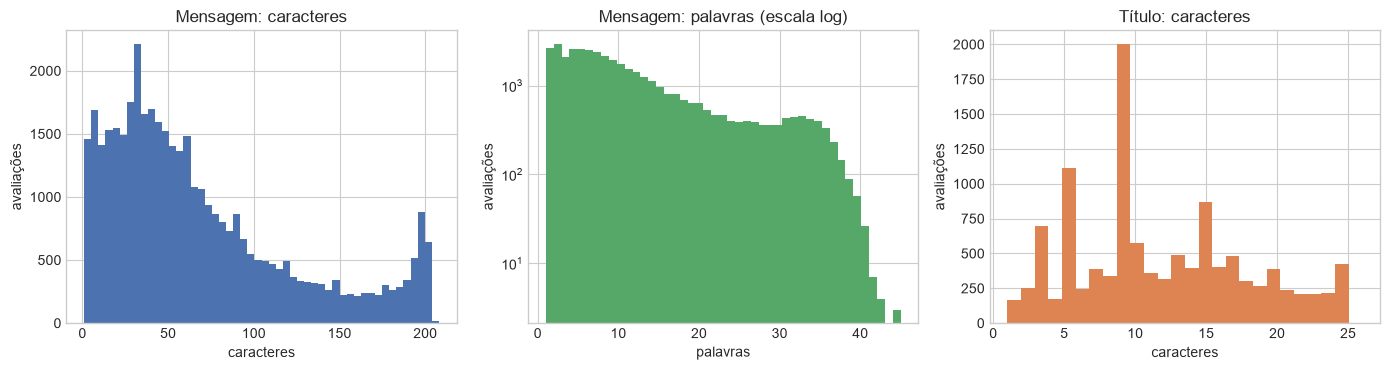

In [5]:
def stats(s):
    nc = s.str.len(); nw = s.str.split().str.len()
    q = [.5, .75, .9, .95, .99]
    out = pd.DataFrame({"caracteres": nc.quantile(q), "palavras": nw.quantile(q)}).T
    out.columns = [f"p{int(x*100)}" for x in q]
    out["média"] = [nc.mean(), nw.mean()]; out["máx"] = [nc.max(), nw.max()]
    return out.round(1)

m = u.loc[u.tem_msg, "mensagem"]; t = u.loc[u.tem_titulo, "titulo"]
print(f"Mensagens (n={len(m):,})"); print(stats(m).to_string())
print(f"\nTítulos (n={len(t):,})"); print(stats(t).to_string())

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].hist(m.str.len(), bins=50, color=AZUL)
ax[0].set(title="Mensagem: caracteres", xlabel="caracteres", ylabel="avaliações")
ax[1].hist(m.str.split().str.len(), bins=45, color=VERDE); ax[1].set_yscale("log")
ax[1].set(title="Mensagem: palavras (escala log)", xlabel="palavras", ylabel="avaliações")
ax[2].hist(t.str.len(), bins=26, color=LARANJA)
ax[2].set(title="Título: caracteres", xlabel="caracteres", ylabel="avaliações")
plt.tight_layout(); plt.savefig(IMAGES_DIR / "02_tamanho_textos.png", dpi=120); plt.show()

**Os textos são curtos e limitados na origem.** A `mensagem` tem mediana de **53 caracteres (9 palavras)**, p99 de 200 e máximo de 208; o `titulo` tem mediana de 10 caracteres e máximo de 26. Como o campo é truncado na coleta, não existe cauda longa: **não precisamos de corte por tamanho máximo**, e cada avaliação cabe inteira em um embedding. O desafio está no outro extremo, os textos curtíssimos.

In [6]:
# Texto da avaliação = título + mensagem (o que seria indexado); título igual à mensagem não é concatenado
igual = u.tem_titulo & u.tem_msg & (u.titulo.str.lower() == u.mensagem.str.lower())
print("Avaliações com título idêntico à mensagem:", int(igual.sum()))
u["texto"] = (u.titulo + ". " + u.mensagem).where(u.tem_titulo & u.tem_msg & ~igual, u.titulo + u.mensagem)
u.loc[igual, "texto"] = u.loc[igual, "mensagem"]
u["texto"] = u.texto.str.strip()
u["nchar"] = u.texto.str.len()
u["n_alnum"] = u.texto.str.count(r"[^\W_]")   # letras e dígitos
base = u[u.tem_texto]

print("Avaliações com texto (únicas):", f"{len(base):,}")
for lim in (3, 5, 10, 15, 20):
    n = int((base.nchar < lim).sum())
    print(f"  texto < {lim:>2} caracteres: {n:>6,}  ({100*n/len(base):.2f}%)")
print("\nCorte por caracteres (< 3):", int((base.nchar < 3).sum()),
      "| corte por alfanuméricos (< 3):", int((base.n_alnum < 3).sum()))
print("Textos com >= 3 caracteres mas < 3 alfanuméricos:", int(((base.nchar >= 3) & (base.n_alnum < 3)).sum()))
for lim in (3, 10):
    r = base[base.nchar < lim]
    print(f"< {lim} caracteres: nota média = {r.review_score.mean():.2f} (base com texto: {base.review_score.mean():.2f})")

Avaliações com título idêntico à mensagem: 266


Avaliações com texto (únicas): 42,370
  texto <  3 caracteres:    352  (0.83%)
  texto <  5 caracteres:  1,069  (2.52%)
  texto < 10 caracteres:  3,703  (8.74%)
  texto < 15 caracteres:  5,456  (12.88%)
  texto < 20 caracteres:  7,401  (17.47%)

Corte por caracteres (< 3): 352 | corte por alfanuméricos (< 3): 413
Textos com >= 3 caracteres mas < 3 alfanuméricos: 61
< 3 caracteres: nota média = 4.39 (base com texto: 3.71)
< 10 caracteres: nota média = 4.53 (base com texto: 3.71)


**Apenas 352 textos (0,83%) têm menos de 3 caracteres e 3.703 (8,7%) têm menos de 10.** Os curtos não são lixo: a nota média deles é 4,53, contra 3,71 na base com texto, o que indica elogios curtos. Também checamos que **266 avaliações têm título idêntico à mensagem**, e que **61 textos têm 3 caracteres ou mais, mas menos de 3 alfanuméricos** (só pontuação ou símbolos); o corte por tamanho bruto deixaria esses 61 passarem. Vamos ver o que domina os textos curtos.

In [7]:
curtos = base[base.nchar < 10]
print("20 textos curtos (< 10 caracteres) mais frequentes (minúsculas):")
print(curtos.texto.str.lower().value_counts().head(20).to_string())
print("\nTextos entre 10 e 19 caracteres (10 mais frequentes):")
print(base[(base.nchar >= 10) & (base.nchar < 20)].texto.str.lower().value_counts().head(10).to_string())

20 textos curtos (< 10 caracteres) mais frequentes (minúsculas):
texto
muito bom    465
bom          416
recomendo    360
ótimo        287
otimo        247
excelente    215
ok           143
boa          121
tudo ok       78
ótima         71
gostei        60
10            60
.             49
otima         48
perfeito      40
adorei        36
muito boa     35
nota 10       30
top           27
amei          23

Textos entre 10 e 19 caracteres (10 mais frequentes):
texto
super recomendo    137
ótimo produto       71
tudo certo          51
bom produto         44
muito bom.          44
entrega rápida      40
gostei muito        38
recomendo.          35
muito bom!          34
satisfeito          31


**Os curtos são elogios genéricos legítimos:** "muito bom" (465), "bom" (416), "recomendo" (360), "ótimo" (287) e "excelente" (215), além de 49 textos que são só um ponto. Por isso o **critério recomendado é descartar textos com menos de 3 caracteres alfanuméricos**: remove os ruídos de pontuação e mantém "bom" e "ok". Textos de 3 a 9 caracteres ficam no índice; o filtro de evidência mínima atua na recuperação, não na carga.

## 5. Datas

Verificamos o intervalo de `review_creation_date` e o volume mensal, no conjunto único e entre as avaliações com texto.

Datas inválidas: 0
Intervalo: 2016-10-02 a 2018-08-31


Meses cobertos: 23 | mês de maior volume: 2018-08 8942
         todas  com texto
mes                      
2016-10    176        121
2016-11    101         79
2016-12     45         35
2017-01    232        118
...
         todas  com texto
mes                      
2018-05   7442       3390
2018-06   6702       3064
2018-07   5604       2502
2018-08   8942       3987


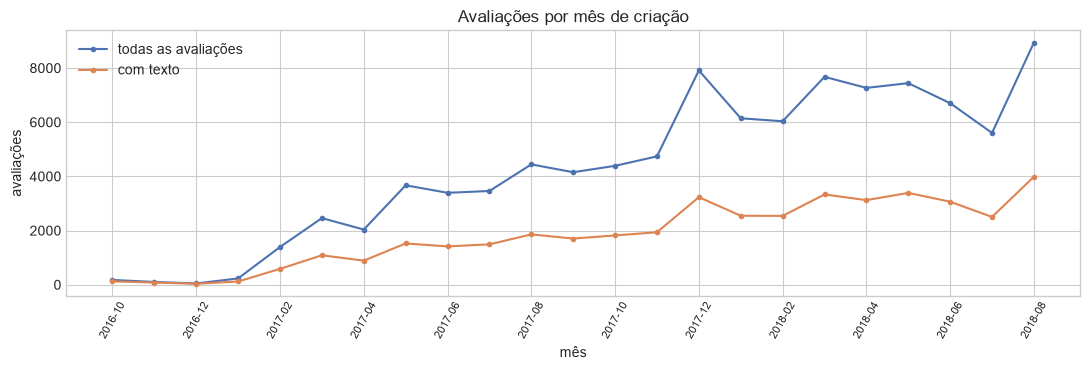

In [8]:
u["data"] = pd.to_datetime(u.review_creation_date, errors="coerce")
print("Datas inválidas:", int(u.data.isna().sum()))
print("Intervalo:", u.data.min().date(), "a", u.data.max().date())
u["mes"] = u.data.dt.to_period("M")
mm = pd.DataFrame({"todas": u.groupby("mes").size(), "com texto": u[u.tem_texto].groupby("mes").size()})
print("Meses cobertos:", len(mm), "| mês de maior volume:", mm.todas.idxmax(), int(mm.todas.max()))
print(mm.head(4).to_string()); print("..."); print(mm.tail(4).to_string())

fig, ax = plt.subplots(figsize=(11, 3.8))
xs = mm.index.astype(str)
ax.plot(xs, mm.todas, color=AZUL, marker="o", ms=3, label="todas as avaliações")
ax.plot(xs, mm["com texto"], color=LARANJA, marker="o", ms=3, label="com texto")
ax.set_xticks(range(0, len(xs), 2)); ax.set_xticklabels(xs[::2], rotation=60, fontsize=8)
ax.set(title="Avaliações por mês de criação", xlabel="mês", ylabel="avaliações"); ax.legend()
plt.tight_layout(); plt.savefig(IMAGES_DIR / "03_volume_mensal.png", dpi=120); plt.show()

**A base cobre 23 meses, de 2016-10-02 a 2018-08-31, sem nenhuma data inválida.** Os 4 primeiros meses (2016-10 a 2017-01) têm volume residual (45 a 232 avaliações por mês, com mínimo de 45 em 2016-12); o último mês, 2018-08, é o pico da série, com **8.942 avaliações**. Para filtros e análises por período, os meses de 2016 devem ser lidos com cautela, pois têm pouco volume.

## 6. Metadados: entrega e categoria

Juntamos as avaliações a `orders` (atraso e dias de entrega) e a `order_items` + `products` (categoria). Definimos **atraso** como `order_delivered_customer_date` (com horário) posterior a `order_estimated_delivery_date`, que está sempre à meia-noite; assim, qualquer entrega no dia estimado, depois das 00:00, conta como atrasada. Mostramos também a comparação por data (dia). Para avaliações ligadas a mais de um pedido, usamos o primeiro `order_id`.

In [9]:
orders = pd.read_csv(DATA_RAW / "olist_orders_dataset.csv",
    parse_dates=["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"])
items = pd.read_csv(DATA_RAW / "olist_order_items_dataset.csv", usecols=["order_id", "order_item_id", "product_id"])
prod = pd.read_csv(DATA_RAW / "olist_products_dataset.csv", usecols=["product_id", "product_category_name"])
trad = pd.read_csv(DATA_RAW / "product_category_name_translation.csv", encoding="utf-8-sig")

ent, est = orders.order_delivered_customer_date, orders.order_estimated_delivery_date
orders["atrasado"] = (ent > est).astype(float).where(ent.notna())
orders["atrasado_dia"] = (ent.dt.normalize() > est.dt.normalize()).astype(float).where(ent.notna())
orders["dias_entrega"] = (ent - orders.order_purchase_timestamp).dt.days

uo = u.merge(orders, on="order_id", how="left", indicator=True)
print("Avaliações sem pedido correspondente em orders:", int((uo._merge == "left_only").sum()))
print("Sem data de entrega:", int(uo.order_delivered_customer_date.isna().sum()),
      f"({100*uo.order_delivered_customer_date.isna().mean():.2f}%)")
print("\nStatus do pedido:"); print(uo.order_status.value_counts().to_string())
print("\nDias de entrega:"); print(uo.dias_entrega.describe().round(1).to_string())

Avaliações sem pedido correspondente em orders: 0
Sem data de entrega: 2803 (2.85%)

Status do pedido:
order_status
delivered      95609
shipped         1027
unavailable      590
canceled         577
invoiced         308
processing       294
created            3
approved           2

Dias de entrega:
count    95607.0
mean        12.0
std          9.5
min          0.0
25%          6.0
50%         10.0
75%         15.0
max        208.0


**Todas as avaliações encontram o pedido em `orders`, mas 2,85% (2.803) não têm `order_delivered_customer_date`**, em geral por status `shipped`, `canceled`, `unavailable` ou `invoiced`. Para esses casos, o atraso e os dias de entrega ficam ausentes e viram `-1` na preparação, sem descartar a avaliação. Entre as entregues, a mediana é de 10 dias (média de 12, máximo de 208).

          count  mean
atrasado             
no prazo  87974  4.30
atrasado   7633  2.57

% atrasadas (horário > data estimada): 7.98%
% atrasadas (comparação por data/dia):  6.65%
Nota média por data/dia: {0.0: 4.29, 1.0: 2.27}


Entre as com texto: 10.73% atrasadas (por dia: 9.43%)


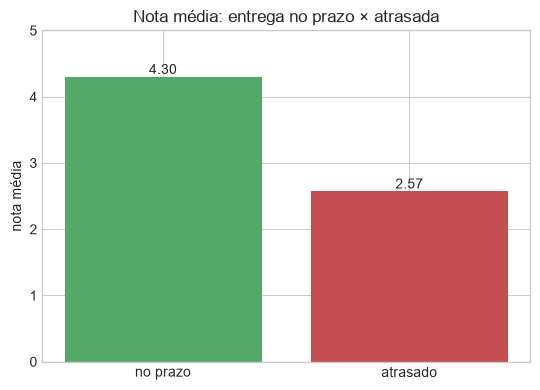

In [10]:
a = uo.dropna(subset=["atrasado"])
res = a.groupby("atrasado").review_score.agg(["count", "mean"]).round(2)
res.index = res.index.map({0.0: "no prazo", 1.0: "atrasado"})
print(res.to_string())
print(f"\n% atrasadas (horário > data estimada): {100*a.atrasado.mean():.2f}%")
print(f"% atrasadas (comparação por data/dia):  {100*a.atrasado_dia.mean():.2f}%")
print("Nota média por data/dia:", a.groupby("atrasado_dia").review_score.mean().round(2).to_dict())
at_txt = uo[uo.tem_texto].dropna(subset=["atrasado"])
print(f"Entre as com texto: {100*at_txt.atrasado.mean():.2f}% atrasadas (por dia: {100*at_txt.atrasado_dia.mean():.2f}%)")

fig, ax = plt.subplots(figsize=(5.5, 4))
bars = ax.bar(["no prazo", "atrasado"], res["mean"], color=[VERDE, VERMELHO])
ax.bar_label(bars, fmt="%.2f", fontsize=10)
ax.set(title="Nota média: entrega no prazo × atrasada", ylabel="nota média", ylim=(0, 5))
plt.tight_layout(); plt.savefig(IMAGES_DIR / "04_atraso_nota.png", dpi=120); plt.show()

**Hipótese testada: o atraso derruba a nota.** As **7.633 avaliações atrasadas (7,98%)** têm nota média de **2,57**, contra 4,30 nas 87.974 entregues no prazo. Se comparamos por data (dia) em vez de horário, o atraso cai para **6,65%** (nota média de 2,27 nas atrasadas), porque entregas feitas no próprio dia estimado deixam de contar. Na preparação, usamos a comparação **por data**, que corresponde ao que o cliente percebe como prazo cumprido, e guardamos `atrasado` como metadado filtrável.

In [11]:
ip = items.merge(prod, on="product_id", how="left")
ip["categoria"] = ip.product_category_name.fillna("desconhecido")
print("Itens sem categoria:", int(ip.product_category_name.isna().sum()), f"({100*ip.product_category_name.isna().mean():.2f}%)")
print("Categorias sem tradução:", sorted(set(ip.product_category_name.dropna()) - set(trad.product_category_name)))

# nº de categorias conhecidas por pedido (pedido só com itens sem categoria conta como 1: "desconhecido")
ncat = ip.dropna(subset=["product_category_name"]).groupby("order_id").categoria.nunique()
ncat = ncat.reindex(ip.order_id.unique()).fillna(1).astype(int)
fl = ip.groupby("order_id").product_category_name.agg(conhecida=lambda s: s.notna().any(), ausente=lambda s: s.isna().any())
print("\nPedidos com itens:", f"{len(ncat):,}")
print("Nº de categorias conhecidas por pedido:"); print(ncat.value_counts().sort_index().to_string())
print("Pedidos com item de categoria conhecida e item sem categoria:", int((fl.conhecida & fl.ausente).sum()))

uo["n_cat"] = uo.order_id.map(ncat)
print("\nAvaliações cujo pedido não tem itens:", int(uo.n_cat.isna().sum()))
print("Avaliações com > 1 categoria conhecida:", int((uo.n_cat > 1).sum()), f"({100*(uo.n_cat > 1).mean():.2f}%)")

# categoria principal: a mais frequente entre os itens; categoria conhecida tem prioridade sobre "desconhecido"
princ = (ip.groupby(["order_id", "categoria"]).size().reset_index(name="n")
         .assign(desc=lambda d: d.categoria.eq("desconhecido"))
         .sort_values(["order_id", "desc", "n", "categoria"], ascending=[True, True, False, True])
         .drop_duplicates("order_id").set_index("order_id").categoria)
uo["categoria"] = uo.order_id.map(princ).fillna("desconhecido")
print("Avaliações sem categoria (inclui pedidos sem itens):", int((uo.categoria == "desconhecido").sum()),
      f"({100*(uo.categoria == 'desconhecido').mean():.2f}%)")
print("Sem categoria entre as com texto:", int(((uo.categoria == "desconhecido") & uo.tem_texto).sum()))

dd = rev[rev.duplicated("review_id", keep=False)].assign(cat=lambda d: d.order_id.map(princ).fillna("desconhecido"))
dif = dd.groupby("review_id").cat.nunique()
print("review_id repetidos com categoria principal diferente entre pedidos:", int((dif > 1).sum()), "de", len(dif))

Itens sem categoria: 1603 (1.42%)


Categorias sem tradução: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']



Pedidos com itens: 98,666
Nº de categorias conhecidas por pedido:
categoria
1    97939
2      712
3       15
Pedidos com item de categoria conhecida e item sem categoria: 62

Avaliações cujo pedido não tem itens: 725
Avaliações com > 1 categoria conhecida: 718 (0.73%)


Avaliações sem categoria (inclui pedidos sem itens): 2107 (2.14%)
Sem categoria entre as com texto: 1110
review_id repetidos com categoria principal diferente entre pedidos: 309 de 789


**Quase todo pedido tem uma única categoria: 97.939 dos 98.666 pedidos com itens.** Há 712 pedidos com duas categorias conhecidas e 15 com três (0,73% das avaliações), e **62 pedidos misturam itens com e sem categoria**; nesses, damos prioridade à categoria conhecida. Ficam sem categoria **2,14% das avaliações (2.107)**, incluindo 725 cujo pedido não tem nenhum item em `order_items`. Como o Chroma não aceita listas em metadados, guardamos a **categoria principal** (a mais frequente entre os itens) e o número de categorias do pedido. A divergência de categoria entre cópias de um mesmo `review_id` é tratada nos achados abertos.

categoria
cama_mesa_banho           4373
beleza_saude              3557
esporte_lazer             3035
informatica_acessorios    2792
relogios_presentes        2585
moveis_decoracao          2581
utilidades_domesticas     2460
telefonia                 1885
automotivo                1768
ferramentas_jardim        1597
cool_stuff                1527
brinquedos                1466
perfumaria                1271
desconhecido              1110
bebes                     1093

Categorias distintas (avaliações com texto): 74
As 15 maiores concentram: 78.1% das avaliações com texto


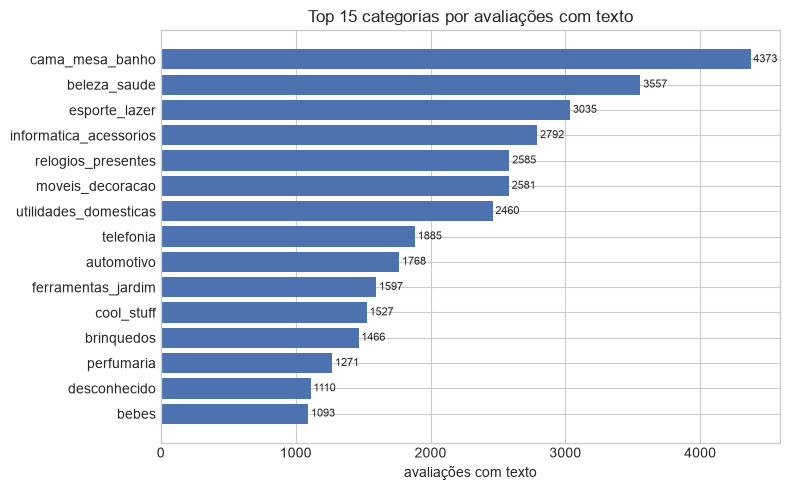

In [12]:
top = uo[uo.tem_texto].categoria.value_counts().head(15)
print(top.to_string())
print("\nCategorias distintas (avaliações com texto):", uo[uo.tem_texto].categoria.nunique())
print("As 15 maiores concentram:", f"{100*top.sum()/uo.tem_texto.sum():.1f}% das avaliações com texto")

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(top.index[::-1], top.values[::-1], color=AZUL)
ax.bar_label(bars, fmt="%d", fontsize=8, padding=2)
ax.set(title="Top 15 categorias por avaliações com texto", xlabel="avaliações com texto")
plt.tight_layout(); plt.savefig(IMAGES_DIR / "05_top_categorias.png", dpi=120); plt.show()

**As 15 maiores categorias concentram 78,1% das avaliações com texto**, entre 74 categorias distintas. `cama_mesa_banho` lidera com 4.373, seguida de `beleza_saude` (3.557) e `esporte_lazer` (3.035). Com 1.110 avaliações com texto, `desconhecido` é a 14ª "categoria": o filtro por categoria deve tratá-lo como valor explícito, não como erro.

## 7. Dados pessoais e ruído de texto

Contamos por expressão regular e-mail, telefone brasileiro, CPF e URL nos campos de título e mensagem. Nos exemplos, o trecho encontrado é substituído por um marcador: nenhum dado pessoal cru é impresso.

In [13]:
txt = u.loc[u.tem_texto, ["review_id", "titulo", "mensagem"]].copy()
txt["campo_todo"] = txt.titulo + " \n " + txt.mensagem

marc = txt.campo_todo.str.findall(r"\[[A-Za-z_ ]{3,15}\]")
print("Textos com marcadores entre colchetes (possível anonimização prévia):", int((marc.str.len() > 0).sum()))

PADROES = {
    "[EMAIL]": r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+",
    "[URL]": r"(?:https?://|www\.)\S+",
    "[CPF]": r"(?<!\d)\d{3}\.?\d{3}\.?\d{3}-?\d{2}(?!\d)",
    "[TELEFONE]": r"(?<!\d)(?:\+?55\s?)?(?:\(?\d{2}\)?[\s.-]?)?9?\d{4}[\s.-]?\d{4}(?!\d)",
}
def sem(s, *rots):
    for r in rots:
        s = re.sub(PADROES[r], " ", s)
    return s

def mascara(s):
    # só para exibir exemplos; na preparação, telefone com DDD vem antes do CPF e o CPF é validado pelo dígito verificador
    for rot in ["[EMAIL]", "[URL]", "[CPF]", "[TELEFONE]"]:
        s = re.sub(PADROES[rot], rot, s)
    return s

res = {}
for rot, pat in PADROES.items():
    base_s = txt.campo_todo
    if rot == "[TELEFONE]":
        base_s = base_s.map(lambda s: sem(s, "[EMAIL]", "[URL]", "[CPF]"))
    elif rot == "[CPF]":
        base_s = base_s.map(lambda s: sem(s, "[EMAIL]", "[URL]"))
    res[rot] = base_s.str.contains(pat, regex=True)
    print(f"{rot:<11} avaliações com ocorrência: {int(res[rot].sum()):>3}  ({100*res[rot].mean():.3f}% dos textos)")
pii_qualquer = res["[EMAIL]"] | res["[CPF]"] | res["[TELEFONE]"]
print("\nAvaliações com e-mail, CPF ou telefone:", int(pii_qualquer.sum()))

for rot in ["[TELEFONE]", "[CPF]", "[URL]"]:
    print(f"\n--- exemplos mascarados: {rot} (até 5) ---")
    for s in txt[res[rot]].head(5).campo_todo:
        print("  ", mascara(s)[:150].replace("\n", " "))

Textos com marcadores entre colchetes (possível anonimização prévia): 0


[EMAIL]     avaliações com ocorrência:   0  (0.000% dos textos)
[URL]       avaliações com ocorrência:   2  (0.005% dos textos)


[CPF]       avaliações com ocorrência:   1  (0.002% dos textos)


[TELEFONE]  avaliações com ocorrência:   5  (0.012% dos textos)

Avaliações com e-mail, CPF ou telefone: 6

--- exemplos mascarados: [TELEFONE] (até 5) ---
      Estpu preocupada, no status de recebimento consta como entregue dia 06/08, porem ainda não recebi o pedido. Inclusive liguei no telefone [TELEFONE]
   Pedido: [TELEFONE] de 21   
 Me ligue [TELEFONE]
   super recomendo [TELEFONE]   produto de ótima qualidade!
 [TELEFONE]

--- exemplos mascarados: [CPF] (até 5) ---
   [CPF]   wol

--- exemplos mascarados: [URL] (até 5) ---
   as cores não corresponde   comprei o produto pela cor ilustrada pelo site da loja americana, no site mostra ser preto [URL] quando o produto chegou aq
      Loja parceira de [URL] e por isso merecedora de crédito.


**A base praticamente não tem dados pessoais: 0 e-mails, 2 URLs, 1 ocorrência do padrão de CPF e 6 do padrão de telefone, em 5 avaliações** (6 avaliações com e-mail, CPF ou telefone), e não há marcadores de anonimização prévia. Os exemplos mostram que o regex também pega o que não é PII, como um número de pedido. Detalhamos abaixo a qualidade dessa detecção.

In [14]:
def valida_cpf(d):
    d = re.sub(r"\D", "", d)
    if len(d) != 11 or d == d[0] * 11:
        return False
    for n in (9, 10):
        dv = (sum(int(d[i]) * (n + 1 - i) for i in range(n)) * 10) % 11 % 10
        if dv != int(d[n]):
            return False
    return True

# telefone: contagem por ocorrência e por formato (a soma fecha com o total)
ph = txt.campo_todo.map(lambda s: sem(s, "[EMAIL]", "[URL]", "[CPF]"))
formato = {"com DDD entre parênteses": 0, "com hífen": 0, "só dígitos": 0, "separado por espaço/ponto": 0}
apos_pedido = 0
for s_ in ph:
    for mt in re.finditer(PADROES["[TELEFONE]"], s_):
        g_ = mt.group()
        k = ("com DDD entre parênteses" if "(" in g_ else "com hífen" if "-" in g_
             else "só dígitos" if re.fullmatch(r"\+?\d+", g_) else "separado por espaço/ponto")
        formato[k] += 1
        apos_pedido += bool(re.search(r"pedido\W*(?:n[ºo°]?\W*)?$", s_[:mt.start()].lower()))
for k, v in formato.items():
    print(f"{k:<28}", v)
print(f"{'total de ocorrências':<28}", sum(formato.values()))
print("Ocorrências precedidas de 'pedido':", apos_pedido)

cpfs = [mt.group() for s_ in txt.campo_todo.map(lambda s: sem(s, "[EMAIL]", "[URL]")) for mt in re.finditer(PADROES["[CPF]"], s_)]
print("\nOcorrências do padrão de CPF:", len(cpfs), "| com dígito verificador válido:", sum(map(valida_cpf, cpfs)))
print("Telefones '(DD) XX-XX-XX-XX' não capturados pelo padrão:",
      int(txt.campo_todo.str.contains(r"\(\d{2}\)\s?\d{2}-\d{2}-\d{2}-\d{2}", regex=True).sum()))

dom = txt.campo_todo.map(lambda s: sem(s, "[EMAIL]", "[URL]")).str.contains(
    r"\b[a-z0-9-]{2,}\.(?:com|net|org)(?:\.br)?\b", case=False, regex=True)
print("\nTextos com URL (http/www):", int(res["[URL]"].sum()), "| textos com domínio solto (algo.com):", int(dom.sum()))

com DDD entre parênteses     0
com hífen                    1
só dígitos                   1
separado por espaço/ponto    4
total de ocorrências         6
Ocorrências precedidas de 'pedido': 1



Ocorrências do padrão de CPF: 1 | com dígito verificador válido: 0
Telefones '(DD) XX-XX-XX-XX' não capturados pelo padrão: 1



Textos com URL (http/www): 2 | textos com domínio solto (algo.com): 158


**Das 5 avaliações com padrão de telefone, 3 trazem telefone real (formatos `XXXX XXXX` e `DD 9XXXX XXXX`, separados por espaço) e 2 são falsos positivos:** um número de pedido no formato `DD-XXXXXXXX` e 8 dígitos soltos num título. O único "CPF" tem **dígito verificador inválido**, então também é falso positivo, e há **1 telefone no formato `(DD) XX-XX-XX-XX` que o padrão não captura**. O padrão de URL só pega `http`/`www` (2 textos); 158 textos citam domínios soltos como `algo.com`, em geral nomes de loja, que não tratamos como PII. Concluímos que o mascaramento por regex é de **melhor esforço**.

In [15]:
c = txt.campo_todo
print("Mensagens com quebra de linha:", int(txt.mensagem.str.contains("\n").sum()),
      "| com \\r\\n:", int(txt.mensagem.str.contains("\r\n").sum()))
print("Textos com tabulação:", int(c.str.contains("\t").sum()))
print("Textos com espaços duplos:", int(c.str.contains(r"[ ]{2,}", regex=True).sum()))
print("HTML residual (tags ou entidades):", int(c.str.contains(r"<[^>]+>|&[a-z]+;|&#\d+;", regex=True).sum()))
print("Letras repetidas 3+ vezes:", int((c.str.findall(r"([A-Za-z])\1{2,}").str.len() > 0).sum()))
print("3+ sinais de pontuação seguidos:", int(c.str.contains(r"[!?.]{3,}", regex=True).sum()))
print("Caracteres fora do Latin-1 (emoji, símbolos):", int(c.str.contains(r"[^\x00-\xff]", regex=True).sum()))
print("Textos em MAIÚSCULAS (>= 10 letras):", int(((c.str.upper() == c) & (c.str.count(r"[A-Za-z]") >= 10)).sum()))

ABREV = ["vc", "pq", "tb", "tbm", "q", "n", "naum", "msm", "p/", "qdo", "vcs", "blz", "td", "obg", "mt"]
low = c.str.lower()
ab = pd.DataFrame([(a_, int(low.str.contains(r"(?<!\w)" + re.escape(a_) + r"(?!\w)", regex=True).sum())) for a_ in ABREV],
                  columns=["abreviação", "textos"]).set_index("abreviação")
ab["%"] = (100 * ab.textos / len(txt)).round(2)
print("\nAbreviações de internet (textos que contêm):"); print(ab.sort_values("textos", ascending=False).to_string())

longos = c.str.len() >= 40
sem_acento = (~c.str.contains(r"[áàâãéêíóôõúç]", case=False, regex=True)) & longos
print("\nTextos longos (>= 40) sem nenhum acento:", int(sem_acento.sum()), f"({100*sem_acento.sum()/longos.sum():.1f}% dos longos)")

Mensagens com quebra de linha: 2678 | com \r\n: 2678
Textos com tabulação: 1
Textos com espaços duplos: 0
HTML residual (tags ou entidades): 0


Letras repetidas 3+ vezes: 271
3+ sinais de pontuação seguidos: 2971
Caracteres fora do Latin-1 (emoji, símbolos): 298


Textos em MAIÚSCULAS (>= 10 letras): 1109



Abreviações de internet (textos que contêm):
            textos     %
abreviação              
q              526  1.24
vcs            230  0.54
pq             198  0.47
n              124  0.29
td             103  0.24
mt              76  0.18
vc              50  0.12
tbm             37  0.09
obg             36  0.08
p/              27  0.06
tb              23  0.05
qdo             20  0.05
msm             16  0.04
blz             11  0.03
naum             1  0.00

Textos longos (>= 40) sem nenhum acento: 8336 (30.0% dos longos)


**O texto é limpo de HTML e de espaços duplos, mas tem ruído de formatação.** **2.678 mensagens trazem quebra de linha `\r\n`**, 2.971 textos têm 3 ou mais sinais de pontuação seguidos, 1.109 estão em maiúsculas e 298 têm emoji ou símbolos. As abreviações mais comuns são `q` (526 textos, 1,24%), `vcs` (230) e `pq` (198); `q` e `n` são ambíguas e uma troca cega pode errar. **Cerca de 30% dos textos longos não têm nenhum acento.** Mantemos acentos e pontuação na versão leve (embedding e LLM) e normalizamos agressivamente só para o BM25.

## 8. Funil da preparação

Aplicamos em sequência deduplicação, seleção com texto e corte, e medimos o que sobra, com o estado dos metadados nos documentos finais.

In [16]:
n_bruto = len(rev)
n_unicos = rev.review_id.nunique()
n_txt = int(u.tem_texto.sum())
n_lt3 = int((u.tem_texto & (u.nchar < 3)).sum())
n_alnum3 = int((u.tem_texto & (u.n_alnum < 3)).sum())
n_lt10 = int((u.tem_texto & (u.nchar < 10)).sum())
funil = pd.DataFrame({"etapa": [
    "linhas brutas", "deduplicar por review_id", "com título ou mensagem",
    "(alternativa) remover textos < 3 caracteres brutos",
    "remover textos < 3 caracteres alfanuméricos (RECOMENDADO)",
    "(alternativa) remover textos < 10 caracteres"],
    "avaliações": [n_bruto, n_unicos, n_txt, n_txt - n_lt3, n_txt - n_alnum3, n_txt - n_lt10]})
funil["% do bruto"] = (100 * funil.avaliações / n_bruto).round(1)
print(funil.to_string(index=False))

fin = uo[uo.tem_texto & (uo.n_alnum >= 3)]
pii_fin = fin.review_id.isin(set(txt.loc[pii_qualquer, "review_id"]))
print("\nDocumentos finais:", f"{len(fin):,}")
print("  sem categoria ('desconhecido'):", int((fin.categoria == "desconhecido").sum()))
print("  sem data de entrega (-1):", int(fin.order_delivered_customer_date.isna().sum()))
print("  com > 1 categoria conhecida no pedido:", int((fin.n_cat > 1).sum()))
print("  com ocorrência do padrão de e-mail/CPF/telefone:", int(pii_fin.sum()))

                                                    etapa  avaliações  % do bruto
                                            linhas brutas       99224       100.0
                                 deduplicar por review_id       98410        99.2
                                   com título ou mensagem       42370        42.7
       (alternativa) remover textos < 3 caracteres brutos       42018        42.3
remover textos < 3 caracteres alfanuméricos (RECOMENDADO)       41957        42.3
             (alternativa) remover textos < 10 caracteres       38667        39.0

Documentos finais: 41,957
  sem categoria ('desconhecido'): 1104
  sem data de entrega (-1): 1866
  com > 1 categoria conhecida no pedido: 455
  com ocorrência do padrão de e-mail/CPF/telefone: 6


**O funil é 99.224 → 98.410 → 42.370 → 41.957 documentos.** A deduplicação tira 814 linhas, a seleção por texto tira 56.040 e o corte de menos de 3 caracteres alfanuméricos tira mais 413 (352 curtos e 61 só de pontuação ou símbolos). Ficam **41.957 documentos (42,3% das linhas brutas)**; o corte por menos de 10 caracteres deixaria 38.667 e descartaria elogios legítimos. Nos documentos finais, 1.104 estão sem categoria, 1.866 sem data de entrega e 455 têm mais de uma categoria.

## 9. Achados abertos (registrados por transparência)

1. **PII por regex é de melhor esforço.** Dos 5 "telefones", 2 são falsos positivos (número de pedido e 8 dígitos soltos); o único "CPF" é inválido; 1 telefone no formato `(DD) XX-XX-XX-XX` não é capturado. Não validamos a cobertura contra um conjunto rotulado.
2. **Categoria divergente em avaliações duplicadas.** Em 309 das 789 avaliações repetidas, a categoria principal difere entre os pedidos ligados; escolher o primeiro `order_id` é uma simplificação.
3. **725 avaliações de pedidos sem itens** em `order_items` ficam sem categoria, e o status delas inclui `canceled` e `unavailable`.
4. **Pedidos com 2+ avaliações:** 551 linhas repetem um `order_id`; não verificamos se são avaliações diferentes do mesmo pedido.
5. **Domínios soltos** (158 textos com `algo.com`) não são cobertos pelo padrão de URL; não os classificamos um a um.
6. **Duas categorias sem tradução** na tabela fornecida: `pc_gamer` e `portateis_cozinha_e_preparadores_de_alimentos`; usamos o nome em português, então só importa se o inglês for necessário.

## 10. Hipóteses analíticas consolidadas

### Decisões com evidência firme

1. **Deduplicação.** Uma linha por `review_id` (99.224 → 98.410): nos 789 ids repetidos, mensagem, título e nota são idênticos.
2. **Seleção e montagem do texto.** Só entram avaliações com título ou mensagem (42.370, ou 43,1% das únicas). Concatenamos título e mensagem; quando são idênticos (266 casos, sem distinguir maiúsculas), usamos um só.
3. **Corte.** Remover textos com menos de 3 caracteres alfanuméricos (413 textos), deixando **41.957 documentos**. Sem corte por tamanho máximo: a mensagem tem no máximo 208 caracteres.
4. **Limpeza leve e agressiva.** A leve (embedding e LLM) normaliza `\r\n` (2.678 mensagens), tabulação e espaços e preserva acentos e pontuação. A agressiva (BM25) usa minúsculas, remove acentos, pontuação e stopwords e aplica radicalização; só nela tratamos abreviações como `vc` e `pq`.
5. **Metadados ausentes.** Nunca descartamos a avaliação: categoria vira `"desconhecido"` (2,14%) e atraso e dias de entrega viram `-1` quando não há data de entrega (2,85%). O Chroma não aceita nulos.
6. **Categoria.** Guardamos a categoria principal (mais frequente entre os itens; conhecida acima de `"desconhecido"`) e o número de categorias do pedido, pois o Chroma não aceita listas (727 pedidos com mais de uma categoria conhecida).
7. **Atraso.** Comparamos por data (dia), não por horário: 6,65% de atrasos contra 7,98%, com nota média de 2,27 nas atrasadas (por data) contra 4,29 no prazo. `atrasado` vira filtro do retriever.
8. **PII.** Mascaramos `[EMAIL]`, `[TELEFONE]`, `[CPF]` e `[URL]` antes de indexar e antes de qualquer envio a um LLM, com melhor esforço: validamos o dígito verificador do CPF, não mascaramos número precedido de "pedido", aplicamos telefone com DDD antes do CPF e incluímos o formato `(DD) XX-XX-XX-XX`.
9. **Filtros do retriever.** Nota (1 a 5), categoria (incluindo `"desconhecido"`), atraso e período (`review_creation_date`, de 2016-10 a 2018-08) são filtros viáveis, com cobertura de metadados acima de 97%.

### Limitações a documentar

1. **Viés de seleção por nota.** Notas 1 e 2 têm 69 a 77% de texto, contra 33 a 38% nas notas 4 e 5 (a nota 5 tem mais texto que a 4); o corpus sobrerrepresenta insatisfação e não estima a satisfação geral.
2. **Período.** Os 4 primeiros meses (2016-10 a 2017-01) têm volume residual (45 a 232 por mês), e o último mês, 2018-08, é o pico (8.942); análises temporais devem sinalizar isso.
3. **Cobertura de PII.** O mascaramento por regex pode deixar passar ou mascarar errado (achados abertos, itens 1 e 5).
4. **Categoria por pedido, não por avaliação.** Em 309 das 789 avaliações duplicadas, a categoria depende do pedido escolhido.
5. **Textos curtos e abreviações.** Cerca de 8,5% dos textos têm menos de 10 caracteres; abreviações ambíguas (`q`, `n`) e a falta de acentos (30% dos textos longos) reduzem a precisão da busca lexical.